# Lab 2 Микитюк Антон Андреевич 2374

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 1 Загрузка датасета

Используется датасет Wine из первой лабораторной работы

In [2]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target

print(f"Размер датасета: {df.shape[0]} записей, {df.shape[1]} столбцов")
print(f"\nПервые 5 записей:")
df.head()

Размер датасета: 178 записей, 14 столбцов

Первые 5 записей:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 2 Добавление нового атрибута

Добавлен атрибут **color_alcohol_ratio** - отношение интенсивности цвета к содержанию алкоголя. Этот показатель характеризует, насколько вино окрашено при данном уровне алкоголя

In [3]:
df['color_alcohol_ratio'] = df['color_intensity'] / df['alcohol']

print("Новый атрибут: color_alcohol_ratio = color_intensity / alcohol\n")
print(df[['alcohol', 'color_intensity', 'color_alcohol_ratio']].describe().round(3))

Новый атрибут: color_alcohol_ratio = color_intensity / alcohol

       alcohol  color_intensity  color_alcohol_ratio
count  178.000          178.000              178.000
mean    13.001            5.058                0.384
std      0.812            2.318                0.166
min     11.030            1.280                0.107
25%     12.362            3.220                0.258
50%     13.050            4.690                0.355
75%     13.678            6.200                0.454
max     14.830           13.000                0.907


## 3 Очистка данных

### 3.1 Проверка и удаление дубликатов

In [4]:
features = list(wine.feature_names) + ['color_alcohol_ratio']

duplicates = df.duplicated(subset=features).sum()
print(f"Количество дубликатов: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates(subset=features)
    print(f"После удаления дубликатов: {df.shape[0]} записей")
else:
    print("Дубликаты не обнаружены")

Количество дубликатов: 0
Дубликаты не обнаружены


### 3.2 Проверка пропущенных значений

In [5]:
missing = df[features].isnull().sum()
total_missing = missing.sum()
print(f"Общее количество пропущенных значений: {total_missing}")

if total_missing > 0:
    print("\nПропуски по атрибутам:")
    print(missing[missing > 0])
    df[features] = df[features].fillna(df[features].median())
    print("\nПропуски заполнены медианными значениями")
else:
    print("Пропущенные значения отсутствуют")

Общее количество пропущенных значений: 0
Пропущенные значения отсутствуют


### 3.3 Обнаружение и удаление выбросов

In [6]:
print("Выбросы по методу IQR:\n")

outlier_mask = pd.Series([False] * len(df), index=df.index)

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    col_outliers = (df[col] < lower) | (df[col] > upper)
    n_outliers = col_outliers.sum()
    if n_outliers > 0:
        print(f"  {col}: {n_outliers} выбросов (диапазон: [{lower:.2f}, {upper:.2f}])")
    outlier_mask |= col_outliers

df_clean = df[~outlier_mask].copy()
print(f"\nДо очистки: {len(df)} записей")
print(f"После удаления выбросов: {len(df_clean)} записей")
print(f"Удалено: {len(df) - len(df_clean)} записей")

Выбросы по методу IQR:

  malic_acid: 3 выбросов (диапазон: [-0.62, 5.30])
  ash: 3 выбросов (диапазон: [1.69, 3.08])
  alcalinity_of_ash: 4 выбросов (диапазон: [10.75, 27.95])
  magnesium: 4 выбросов (диапазон: [59.50, 135.50])
  proanthocyanins: 2 выбросов (диапазон: [0.20, 3.00])
  color_intensity: 4 выбросов (диапазон: [-1.25, 10.67])
  hue: 1 выбросов (диапазон: [0.28, 1.63])
  color_alcohol_ratio: 8 выбросов (диапазон: [-0.04, 0.75])

До очистки: 178 записей
После удаления выбросов: 157 записей
Удалено: 21 записей


Датасет очищен, выбросы удалены методом межквартильного размаха (IQR). Удалённые 21 запись (11.8%) содержали экстремальные значения за границами IQR хотя бы по одному из 8 атрибутов - их удаление допустимо, так как выбросы искажают расстояния при кластеризации

## 4 Графики зависимостей переменных

Построим графики зависимостей между переменными и опишем наблюдаемые кластеры

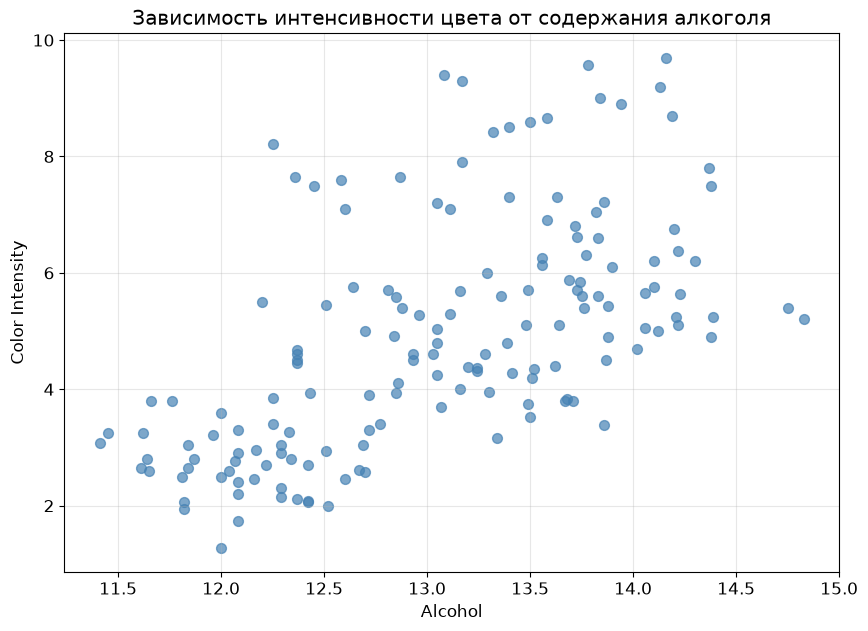

In [7]:
plt.figure(figsize=(10, 7))
plt.scatter(df_clean['alcohol'], df_clean['color_intensity'], alpha=0.7, s=50, color='steelblue')
plt.xlabel('Alcohol')
plt.ylabel('Color Intensity')
plt.title('Зависимость интенсивности цвета от содержания алкоголя')
plt.grid(True, alpha=0.3)
plt.show()

На графике выделяются 2–3 группы точек:
- с высоким алкоголем (> 13.5) и высокой интенсивностью цвета (> 7);
- со средним алкоголем (12 - 13) и низкой интенсивностью цвета (< 4);
- третья группа расположена в средней зоне между двумя другими.

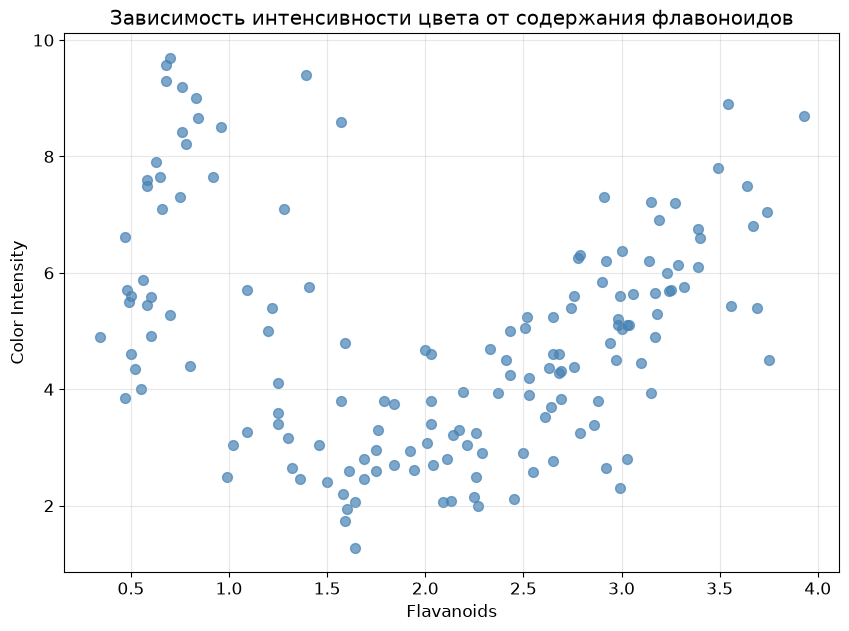

In [8]:
plt.figure(figsize=(10, 7))
plt.scatter(df_clean['flavanoids'], df_clean['color_intensity'], alpha=0.7, s=50, color='steelblue')
plt.xlabel('Flavanoids')
plt.ylabel('Color Intensity')
plt.title('Зависимость интенсивности цвета от содержания флавоноидов')
plt.grid(True, alpha=0.3)
plt.show()

Хорошо заметны три кластера: 
- высокие флавоноиды и средняя интенсивность цвета (справа);
- средние флавоноиды и низкая интенсивность цвета (центр);
- низкие флавоноиды и средне-высокая интенсивность цвета (слева).

Прослеживается отрицательная зависимость

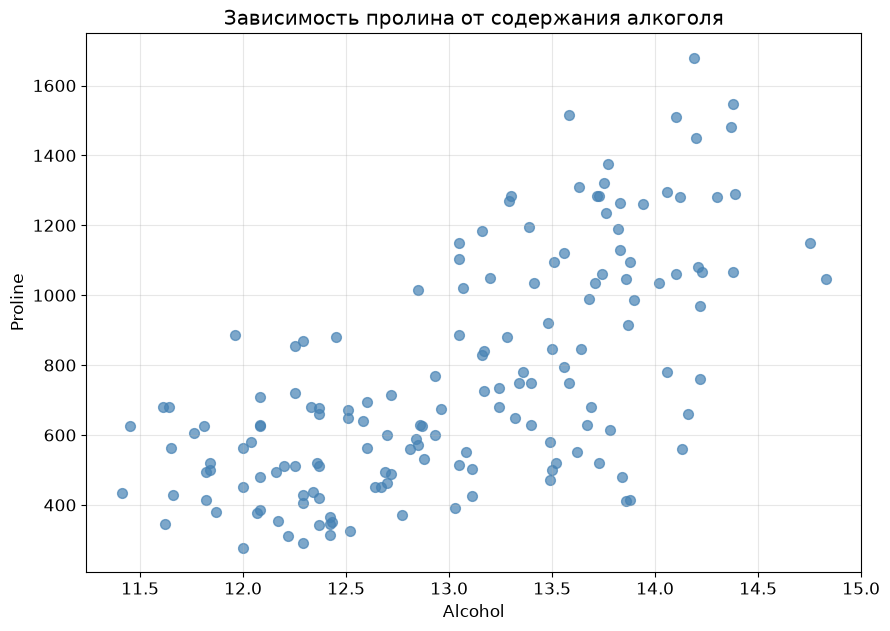

In [9]:
plt.figure(figsize=(10, 7))
plt.scatter(df_clean['alcohol'], df_clean['proline'], alpha=0.7, s=50, color='steelblue')
plt.xlabel('Alcohol')
plt.ylabel('Proline')
plt.title('Зависимость пролина от содержания алкоголя')
plt.grid(True, alpha=0.3)
plt.show()

Видна положительная зависимость - вина с высоким содержанием алкоголя чаще имеют высокий уровень пролина
Выделяется группа в верхнем правом углу (alcohol > 13, proline > 1000) и группа в нижнем левом (alcohol < 13, proline < 750)
Третья группа размещена между ними (alcohol 13 - 14.5, proline > 1000)

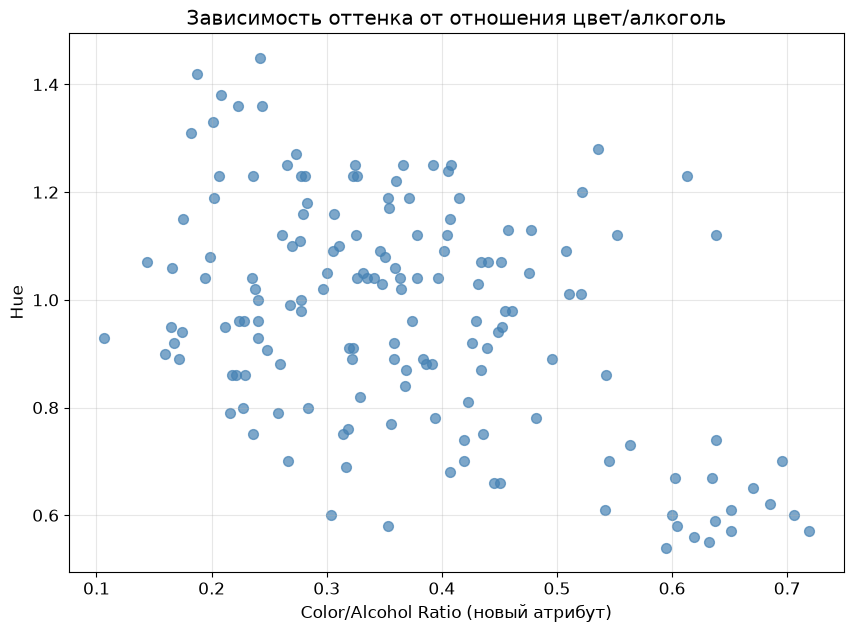

In [10]:
plt.figure(figsize=(10, 7))
plt.scatter(df_clean['color_alcohol_ratio'], df_clean['hue'], alpha=0.7, s=50, color='steelblue')
plt.xlabel('Color/Alcohol Ratio (новый атрибут)')
plt.ylabel('Hue')
plt.title('Зависимость оттенка от отношения цвет/алкоголь')
plt.grid(True, alpha=0.3)
plt.show()

Новый атрибут (color_alcohol_ratio) позволяет увидеть две ярко выраженные группы: вина с высоким оттенком и низким соотношением цвет/алкоголь (слева сверху), и вина с низким оттенком и высоким соотношением (справа снизу), между ними - переходная группа

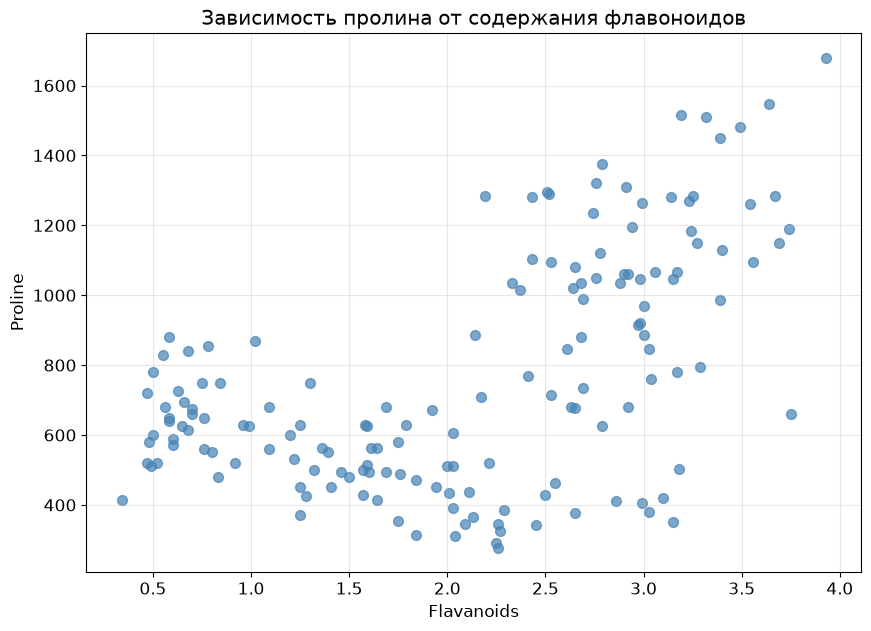

In [11]:
plt.figure(figsize=(10, 7))
plt.scatter(df_clean['flavanoids'], df_clean['proline'], alpha=0.7, s=50, color='steelblue')
plt.xlabel('Flavanoids')
plt.ylabel('Proline')
plt.title('Зависимость пролина от содержания флавоноидов')
plt.grid(True, alpha=0.3)
plt.show()

На графике видны три группы: 
- высокие флавоноиды и высокий пролин (правый верхний угол);
- низкие флавоноиды и низкий пролин (левый нижний угол);
- средние флавоноиды и низкий пролин (посередине между ними).

### Итоги анализа

На графиках чётко прослеживаются 2–3 группы (кластера). Наиболее выразительное разделение наблюдается на графиках:
- flavanoids и color_intensity - три группы разделены наиболее чётко
- alcohol и proline - две-три группы с положительной корреляцией
- color_alcohol_ratio и hue - новый атрибут помогает визуализировать разделение

Предположительно, эти кластеры соответствуют трём сортам вин в датасете

## 5 Применение метода KMeans

### 5.1 Подготовка данных (стандартизация)

Перед применением K-Means необходимо стандартизировать признаки, так как алгоритм использует евклидово расстояние, чувствительное к масштабу

In [12]:
X = df_clean[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Размер данных для кластеризации: {X_scaled.shape}")
print(f"\nСреднее после стандартизации (первые 5 признаков):")
print(np.round(X_scaled.mean(axis=0)[:5], 4))
print(f"\nСКО после стандартизации (первые 5 признаков):")
print(np.round(X_scaled.std(axis=0)[:5], 4))

Размер данных для кластеризации: (157, 14)

Среднее после стандартизации (первые 5 признаков):
[-0.  0.  0.  0. -0.]

СКО после стандартизации (первые 5 признаков):
[1. 1. 1. 1. 1.]


### 5.2 Метод локтя

Метод локтя помогает определить оптимальное число кластеров. Строим график зависимости суммы квадратов расстояний (inertia) от количества кластеров и ищем «изгиб» - точку, после которой добавление кластеров даёт незначительное улучшение

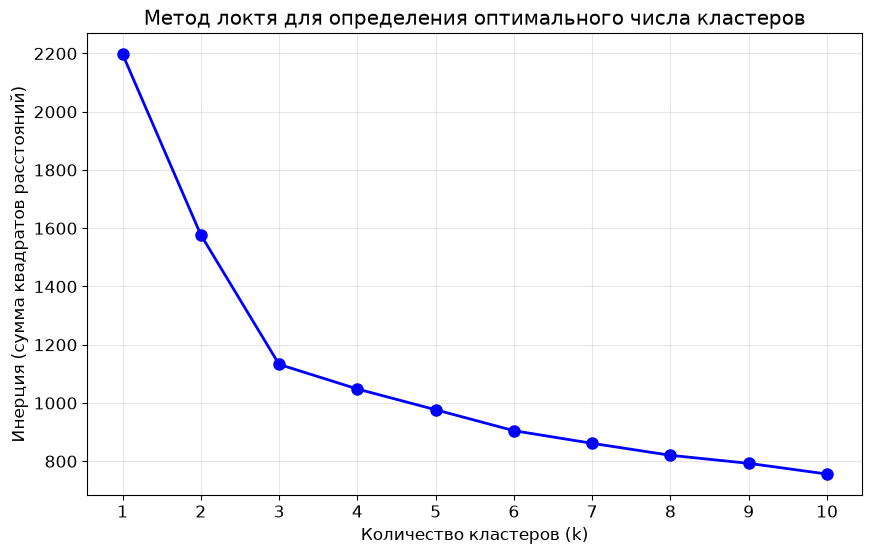

In [13]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Инерция (сумма квадратов расстояний)')
plt.title('Метод локтя для определения оптимального числа кластеров')
plt.xticks(K_range)
plt.grid(True, alpha=0.3)
plt.show()

На графике видно, что наиболее заметный изгиб (локоть) находится при k = 3
Начиная с 3 кластеров, снижение инерции замедляется, что подтверждает наличие трёх естественных групп в данных

### 5.2.1 Метод силуэта

Силуэтный коэффициент показывает, насколько хорошо каждый объект соответствует своему кластеру
Вычислим его для различных значений k и выберем оптимальное

  k=2: Silhouette Score = 0.257
  k=3: Silhouette Score = 0.305
  k=4: Silhouette Score = 0.236
  k=5: Silhouette Score = 0.203
  k=6: Silhouette Score = 0.161


  k=7: Silhouette Score = 0.153
  k=8: Silhouette Score = 0.155
  k=9: Silhouette Score = 0.155
  k=10: Silhouette Score = 0.154


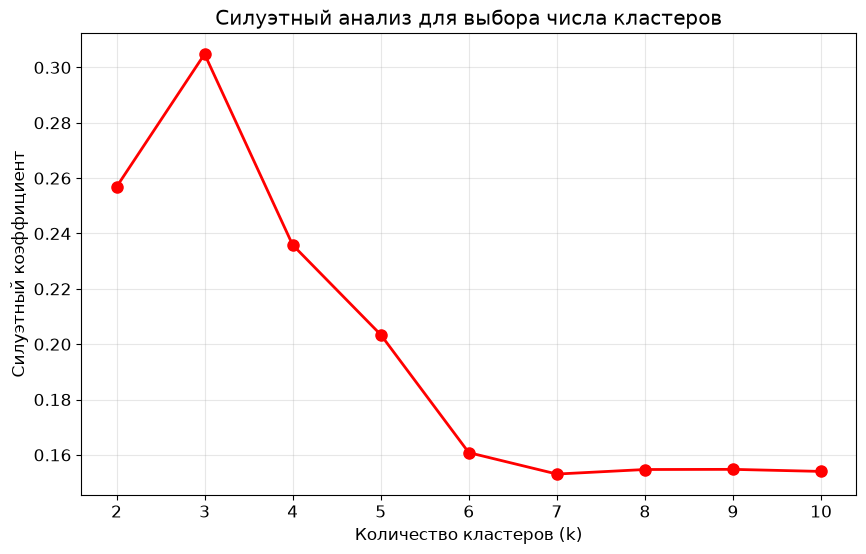

In [14]:
sil_scores = []
K_sil = range(2, 11)

for k in K_sil:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_temp = kmeans_temp.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_temp)
    sil_scores.append(score)
    print(f"  k={k}: Silhouette Score = {score:.3f}")

plt.figure(figsize=(10, 6))
plt.plot(K_sil, sil_scores, 'ro-', linewidth=2, markersize=8)
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Силуэтный коэффициент')
plt.title('Силуэтный анализ для выбора числа кластеров')
plt.xticks(K_sil)
plt.grid(True, alpha=0.3)
plt.show()

Максимальный силуэтный коэффициент достигается при k = 3 (0.305), что подтверждает результат метода локтя. Значение умеренно низкое из-за высокой размерности данных (14 признаков) и естественного перекрытия кластеров
Оба метода указывают на три кластера как оптимальное число

### 5.3 Кластеризация K-Means (k = 3)

In [15]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df_clean['cluster'] = clusters

print("Распределение по кластерам:")
print(df_clean['cluster'].value_counts().sort_index())
print(f"\nФорма матрицы центров кластеров: {kmeans.cluster_centers_.shape}")

Распределение по кластерам:
cluster
0    40
1    60
2    57
Name: count, dtype: int64

Форма матрицы центров кластеров: (3, 14)


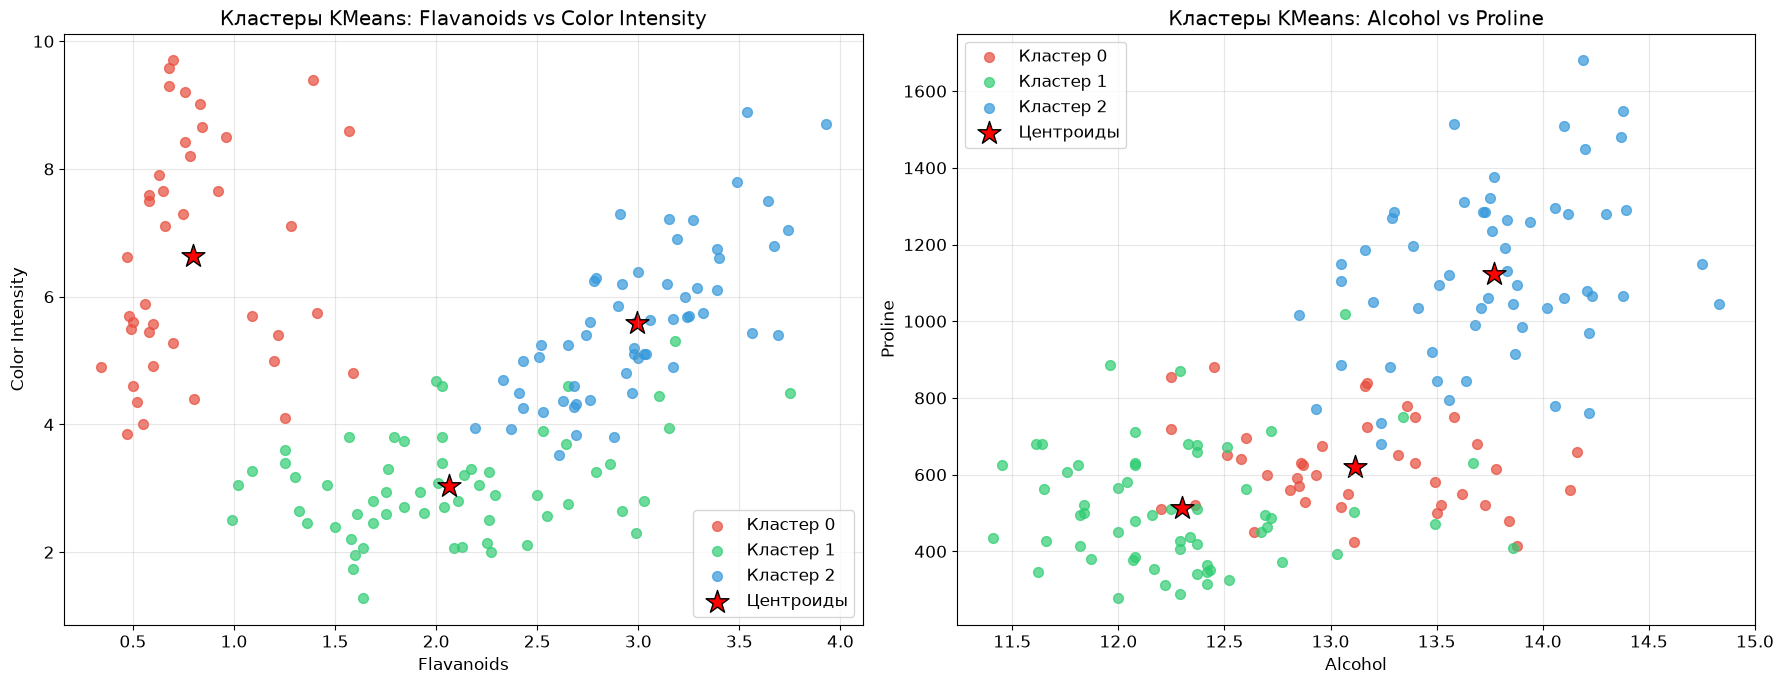

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

colors = ['#e74c3c', '#2ecc71', '#3498db']
centroids_orig = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
)

# Plot 1: flavanoids vs color_intensity
for i in range(3):
    mask = df_clean['cluster'] == i
    axes[0].scatter(df_clean.loc[mask, 'flavanoids'],
                    df_clean.loc[mask, 'color_intensity'],
                    c=colors[i], label=f'Кластер {i}', alpha=0.7, s=50)
axes[0].scatter(centroids_orig['flavanoids'], centroids_orig['color_intensity'],
                c='red', marker='*', s=300, edgecolors='black', linewidths=1, label='Центроиды')
axes[0].set_xlabel('Flavanoids')
axes[0].set_ylabel('Color Intensity')
axes[0].set_title('Кластеры KMeans: Flavanoids vs Color Intensity')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: alcohol vs proline
for i in range(3):
    mask = df_clean['cluster'] == i
    axes[1].scatter(df_clean.loc[mask, 'alcohol'],
                    df_clean.loc[mask, 'proline'],
                    c=colors[i], label=f'Кластер {i}', alpha=0.7, s=50)
axes[1].scatter(centroids_orig['alcohol'], centroids_orig['proline'],
                c='red', marker='*', s=300, edgecolors='black', linewidths=1, label='Центроиды')
axes[1].set_xlabel('Alcohol')
axes[1].set_ylabel('Proline')
axes[1].set_title('Кластеры KMeans: Alcohol vs Proline')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.3.1 Профилирование кластеров

Рассмотрим средние значения признаков в каждом кластере, чтобы понять, что характеризует каждую группу вин

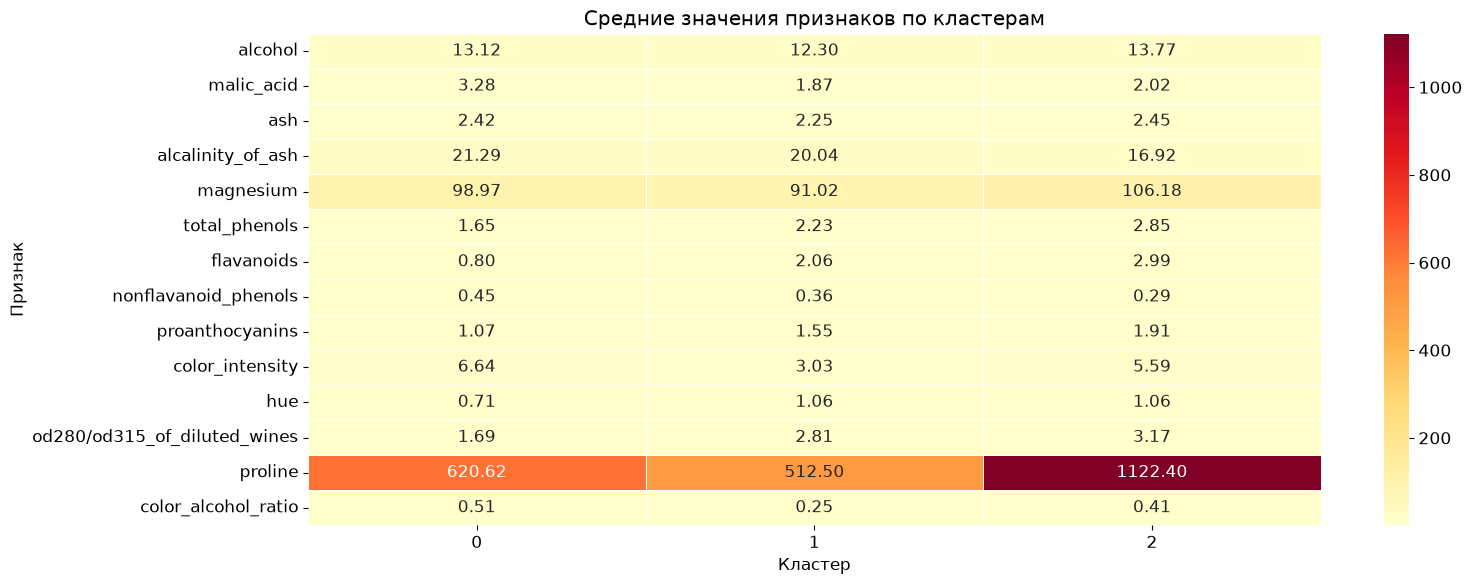

In [17]:
cluster_profile = df_clean.groupby('cluster')[features].mean()

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(cluster_profile.T, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, ax=ax)
ax.set_title('Средние значения признаков по кластерам')
ax.set_xlabel('Кластер')
ax.set_ylabel('Признак')
plt.tight_layout()
plt.show()

**Описание кластеров:**

- Кластер 0 - плотные, мощные красные вина с высоким алкоголем и пролином, высокая интенсивность цвета при низком оттенке указывает на сдвиг от молодого фиолетового к зрелому красному тону;
- Кластер 1 - сбалансированные столовые вина со средними значениями большинства признаков (умеренный алкоголь, средняя интенсивность цвета);
- Кластер 2 - лёгкие красные вина, бледный прозрачный цвет (низкая интенсивность), но богатая фенольная структура (высокие флавоноиды) и высокий параметр оттенка.

Нумерация кластеров может отличаться от нумерации истинных классов

### 5.3.2 Box-plot анализ кластеров

Box-plot графики позволяют наглядно сравнить распределение ключевых признаков в каждом кластере

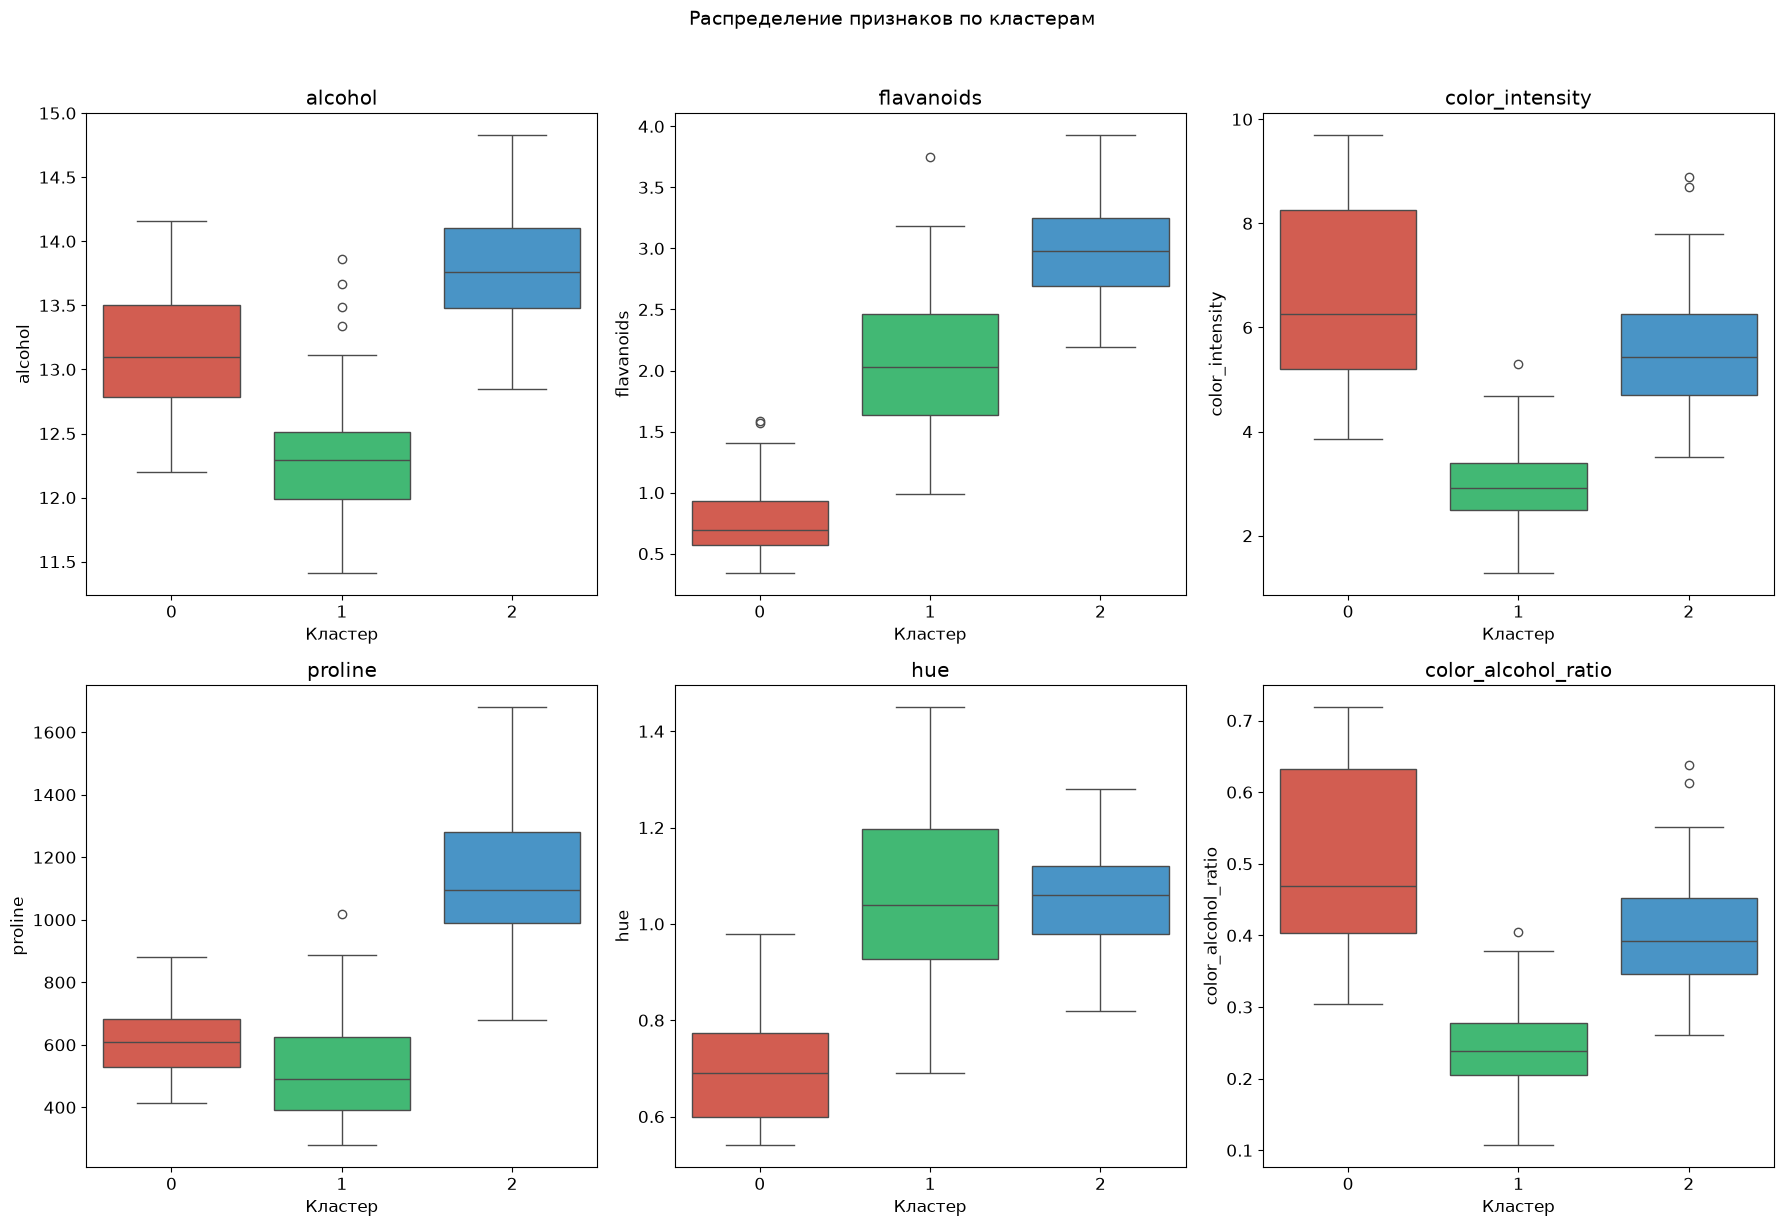

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
key_features = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'hue', 'color_alcohol_ratio']

for idx, feat in enumerate(key_features):
    ax = axes[idx // 3][idx % 3]
    sns.boxplot(x='cluster', y=feat, data=df_clean, palette=['#e74c3c', '#2ecc71', '#3498db'], ax=ax)
    ax.set_title(feat)
    ax.set_xlabel('Кластер')

plt.suptitle('Распределение признаков по кластерам', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Box-plot графики подтверждают различия между кластерами: каждый кластер имеет характерный профиль по ключевым признакам
Медианы и размах значений заметно различаются между группами

### 5.3.3 Визуализация границ кластеров

Для визуализации границ решений KMeans обучена отдельная модель на двух признаках (flavanoids и color_intensity). Нумерация кластеров здесь может не совпадать с основной моделью, обученной на всех 14 признаках. Области закрашены цветом соответствующего кластера, центроиды отмечены звёздочками

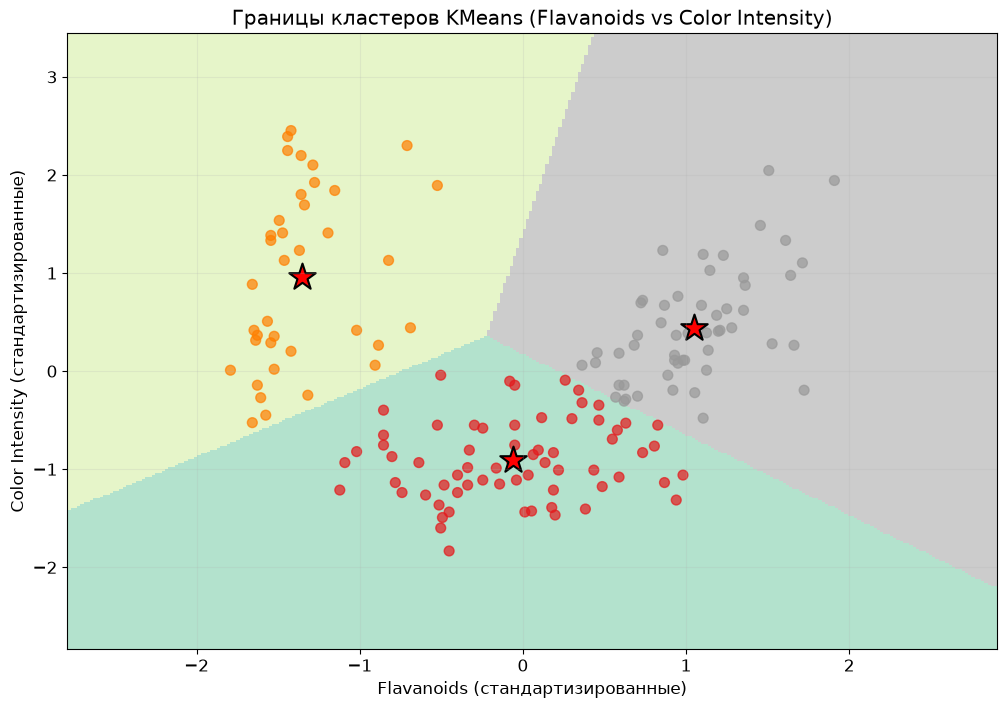

In [19]:
# KMeans на 2 признаках для визуализации границ
feat_idx_x = features.index('flavanoids')
feat_idx_y = features.index('color_intensity')

X_2d = df_clean[['flavanoids', 'color_intensity']].values
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

kmeans_2d = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_2d.fit(X_2d_scaled)

# Meshgrid для границ
h = 0.02
x_min, x_max = X_2d_scaled[:, 0].min() - 1, X_2d_scaled[:, 0].max() + 1
y_min, y_max = X_2d_scaled[:, 1].min() - 1, X_2d_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = kmeans_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(12, 8))
plt.imshow(Z, interpolation='nearest',
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap=plt.cm.Pastel2, aspect='auto', origin='lower')

labels_2d = kmeans_2d.labels_
plt.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=labels_2d, cmap='Set1', s=50, alpha=0.7)
plt.scatter(kmeans_2d.cluster_centers_[:, 0], kmeans_2d.cluster_centers_[:, 1],
            c='red', marker='*', s=400, edgecolors='black', linewidths=1.5)
plt.xlabel('Flavanoids (стандартизированные)')
plt.ylabel('Color Intensity (стандартизированные)')
plt.title('Границы кластеров KMeans (Flavanoids vs Color Intensity)')
plt.grid(True, alpha=0.2)
plt.show()

### 5.4 Оценка качества кластеризации

In [20]:
sil_score = silhouette_score(X_scaled, clusters)
print(f"Силуэтный коэффициент (Silhouette Score): {sil_score:.3f}")
print("(значения от -1 до 1, чем ближе к 1 - тем лучше разделение)")

Силуэтный коэффициент (Silhouette Score): 0.305
(значения от -1 до 1, чем ближе к 1 — тем лучше разделение)


### 5.5 Сравнение с истинными классами

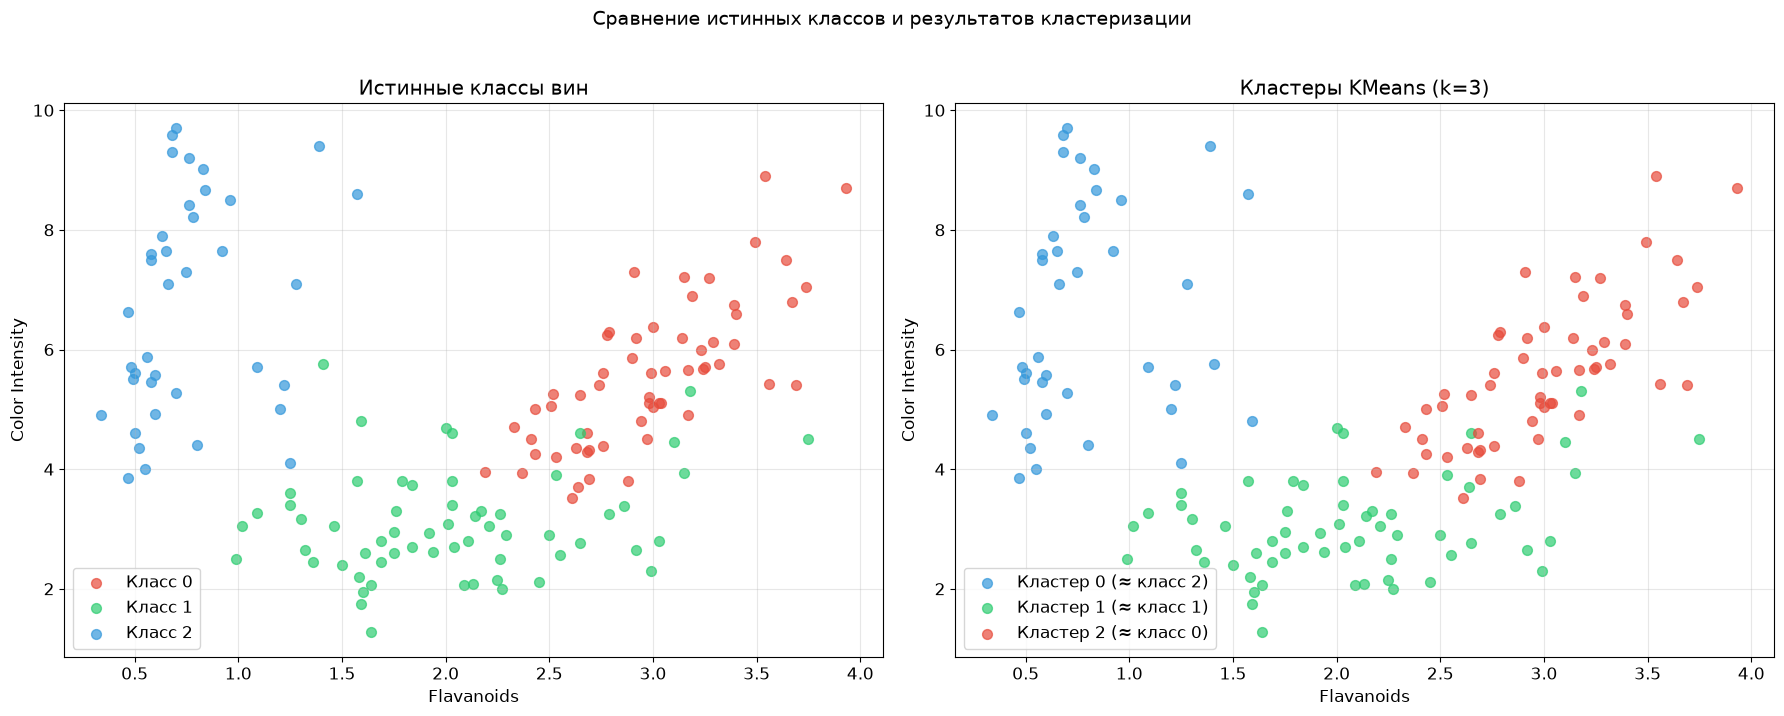

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Динамическое сопоставление кластеров и истинных классов
ct = pd.crosstab(df_clean['target'], df_clean['cluster'])
cluster_to_class = ct.idxmax(axis=0).to_dict()

# Левый график: истинные классы
for i in range(3):
    mask = df_clean['target'] == i
    axes[0].scatter(df_clean.loc[mask, 'flavanoids'],
                    df_clean.loc[mask, 'color_intensity'],
                    c=colors[i], label=f'Класс {i}', alpha=0.7, s=50)
axes[0].set_xlabel('Flavanoids')
axes[0].set_ylabel('Color Intensity')
axes[0].set_title('Истинные классы вин')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Правый график: кластеры с цветами, совпадающими с истинными классами
for i in range(3):
    mask = df_clean['cluster'] == i
    matched_class = cluster_to_class[i]
    axes[1].scatter(df_clean.loc[mask, 'flavanoids'],
                    df_clean.loc[mask, 'color_intensity'],
                    c=colors[matched_class], label=f'Кластер {i} (≈ класс {matched_class})', alpha=0.7, s=50)
axes[1].set_xlabel('Flavanoids')
axes[1].set_ylabel('Color Intensity')
axes[1].set_title('Кластеры KMeans (k=3)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Сравнение истинных классов и результатов кластеризации', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [22]:
print("Таблица соответствия кластеров и истинных классов:\n")
ct = pd.crosstab(df_clean['target'], df_clean['cluster'],
                 rownames=['Истинный класс'], colnames=['Кластер'])
print(ct)

Таблица соответствия кластеров и истинных классов:

Кластер          0   1   2
Истинный класс            
0                0   1  57
1                2  59   0
2               38   0   0


Кластеры, найденные алгоритмом K-Means, в значительной степени совпадают с истинными классами вин. Таблица соответствия показывает, что каждый кластер преимущественно содержит образцы одного класса, хотя нумерация кластеров может не совпадать с нумерацией классов

## 6 Выводы

1. Датасет Wine хорошо подходит для задачи кластеризации, данные содержат три естественные группы, соответствующие сортам вина;

2. Новый атрибут color_alcohol_ratio отражает соотношение окраски вина и содержания алкоголя, помогает визуализировать различия между группами;

3. Очистка данных: дубликаты и пропуски не обнаружены, выбросы удалены по методу IQR;

4. Визуальный анализ графиков рассеивания показал наличие 2–3 различимых групп, наиболее чёткое разделение - по парам flavanoids–color_intensity и alcohol–proline;

5. Метод локтя и силуэтный анализ подтвердили, что оптимальное число кластеров равно трём;

6. K-Means (k=3) разделил данные на три кластера, соответствующие типам вин: выдержанные (высокий алкоголь, пролин, интенсивность цвета), сбалансированные (средние значения) и лёгкие (высокие флавоноиды, низкая интенсивность цвета);

7. Таблица соответствия показывает высокое совпадение кластеров с истинными классами вин.